# 0. Environment Setup

In [1]:
# Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os

import sys
sys.path.insert(0, '..')

from src.config import (RAW_DATA_DIR, ROOT_DIR, PROCESSED_DATA_DIR, MODELS_DIR)

# Show all columns 
pd.set_option('display.max_columns', None)

# Bold Text Setup
b_start = '\033[1m'
b_end = '\033[0m'

# Graph visual style
sns.set_theme(style='whitegrid')

print('Environment Ready')

Environment Ready


-----
# 1. Datasets Loading

In [2]:
# Enriched Complaint Dataset Load
print('Dataframe Loading...')

fraud_complaints = pd.read_csv(fr'{PROCESSED_DATA_DIR}\fraud_topic_enriched_complaints.csv', low_memory=False, delimiter=';')
fraud_complaints["date_received"] = pd.to_datetime(fraud_complaints["date_received"])

print('Dataframe Correctly Loaded')
print()
display(fraud_complaints.sample(3))
print()

# Daily Complaints grouping
grouped_complaints = fraud_complaints.groupby((pd.Grouper(key="date_received", freq="D"))).size().rename("fraud_complaint_volume")
display(grouped_complaints.head())

Dataframe Loading...
Dataframe Correctly Loaded



,date_received,product,sub_product,issue,sub_issue,consumer_complaint_narrative,company,state,zip_code,tags,submitted_via,date_sent_to_company,company_response_to_consumer,timely_response,complaint_id,month_received,topic,topic_prob,count,topic_name,representation,representative_docs
15591,2018-09-13,Credit card or prepaid card,General-purpose credit card or charge card,"Advertising and marketing, including promotion...",Confusing or misleading advertising about the ...,i went online to check my credit with and i fo...,AVANT CREDIT CORPORATION,OH,44092.0,Older American,Web,2018-09-19,Closed with explanation,Yes,3018393,2018-09-01,16,0.930831,891,16_police_pin_fraud_stolen,"['police', 'pin', 'fraud', 'stolen', 'charges'...",['on my wallet was missing with my card that w...
11268,2020-08-28,Credit card or prepaid card,General-purpose credit card or charge card,Problem with a purchase shown on your statement,Credit card company isn't resolving a dispute ...,on i purchased roundtrip tickets to set to lea...,BARCLAYS BANK DELAWARE,CA,91911.0,Servicemember,Web,2020-08-28,Closed with explanation,Yes,3818008,2020-08-01,6,0.583472,1876,6_barclays_barclay_barclaycard_uber,"['barclays', 'barclay', 'barclaycard', 'uber',...",['dollar payment was made on to barclays bank ...
11788,2019-01-23,Credit card or prepaid card,General-purpose credit card or charge card,Problem when making payments,Problem during payment process,barclays bank delaware is harassing me claimin...,BARCLAYS BANK DELAWARE,NY,11204.0,NaN,Web,2019-01-23,Closed with explanation,Yes,3131212,2019-01-01,6,0.955693,1876,6_barclays_barclay_barclaycard_uber,"['barclays', 'barclay', 'barclaycard', 'uber',...",['dollar payment was made on to barclays bank ...


date_received
2017-01-01     2
2017-01-02     4
2017-01-03     4
2017-01-04    12
2017-01-05     7
Freq: D, Name: fraud_complaint_volume, dtype: int64

In [3]:
# Enriched Transactions Dataset Load
print('Dataframe Loading...')

transactions = pd.read_csv(fr'{PROCESSED_DATA_DIR}\anomaly_classification_enriched.csv', low_memory=False, delimiter=';')
transactions["date"] = pd.to_datetime("2020-01-01") + pd.to_timedelta(transactions["Time"], unit="s")
transactions['anomaly_ae'] = (transactions['ae_anomaly_score'] > 0.1).astype(int)

print('Dataframe Correctly Loaded')
print()
display(transactions.sample(3))
print()

# Daily Complaints grouping
grouped_transactions = transactions.groupby(pd.Grouper(key="date", freq="D")).agg(
        total_transactions=("Amount", "count"),
        autoencoder_anomaly=("anomaly_ae", "sum"),
        confirmed_fraud=("Class", "sum")
    )
display(grouped_transactions.head())

Dataframe Loading...
Dataframe Correctly Loaded



,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class,scaled_amount,scaled_time,ae_anomaly_score,if_anomaly_score,xgb_predicted_fraud_prob,date,anomaly_ae
203365,134788.0,-1.647526,2.485940,-2.532589,-1.188529,1.508759,-0.858821,1.419543,-0.551779,0.666759,1.823881,0.963682,0.341969,0.297055,-1.356408,-0.691484,0.164885,-0.143261,0.517305,-0.093889,0.365762,0.086128,0.530105,-0.076657,0.128061,-0.701787,0.178954,-1.498311,-0.630740,1.54,0,-0.347072,0.841772,0.002148,-0.433339,0.000210,2020-01-02 13:26:28,0
42902,41289.0,0.689574,-1.682200,0.521581,-1.592422,-1.835762,-0.677592,-0.445689,0.096514,2.632243,-1.662520,1.051841,1.153645,-1.769777,0.213284,0.108214,-1.068427,0.291086,0.565499,1.601825,0.330086,0.051718,-0.144814,-0.255118,0.539240,0.398870,-0.891306,0.045374,0.066601,272.78,0,0.737369,-1.127122,0.003566,-0.455260,0.002311,2020-01-01 11:28:09,0
207040,136492.0,2.170148,-0.708137,-1.714654,-0.685599,-0.000930,-0.412147,-0.235468,-0.311161,-0.673652,0.930194,-1.483311,-0.052325,1.243233,0.049631,0.534991,-1.213810,-0.568302,1.298106,-0.739846,-0.419226,-0.157886,0.040416,0.025688,0.086026,0.058478,0.798528,-0.070280,-0.055675,49.41,0,-0.155684,0.877655,0.003007,-0.403967,0.000031,2020-01-02 13:54:52,0


,total_transactions,autoencoder_anomaly,confirmed_fraud
date,,,
2020-01-01,144786,263,281
2020-01-02,140021,177,211


In [4]:
# Information Merge
merged = pd.concat([grouped_complaints, grouped_transactions], axis=1).fillna(0)
display(merged)

,fraud_complaint_volume,total_transactions,autoencoder_anomaly,confirmed_fraud
2017-01-01,2,0.0,0.0,0.0
2017-01-02,4,0.0,0.0,0.0
2017-01-03,4,0.0,0.0,0.0
2017-01-04,12,0.0,0.0,0.0
2017-01-05,7,0.0,0.0,0.0
...,...,...,...,...
2021-10-27,7,0.0,0.0,0.0
2021-10-28,3,0.0,0.0,0.0
2021-10-29,9,0.0,0.0,0.0
2021-10-30,3,0.0,0.0,0.0


In [5]:
# Generate synthetic anomaly series based on Autoencoder behavior
np.random.seed(42)

# Assumption: Daily anomaly base rate ~50 transactions
base_anomalies = np.random.poisson(lam=50, size=len(grouped_complaints))

# Injected correlation with random lag
lagged_complaints = grouped_complaints.shift(3).fillna(grouped_complaints.mean())
noise = np.random.normal(0, 5, size=len(grouped_complaints))

# Simulated series with timeframe overlap
sync_anomalies = (base_anomalies + (lagged_complaints * 1.5) + noise).clip(lower=0).round(0)

# Dataframe integrating changes
synthetic_merged = pd.DataFrame({
    "fraud_complaint_volume": grouped_complaints,
    "autoencoder_anomaly": sync_anomalies
}, index=grouped_complaints.index)

synthetic_merged = synthetic_merged.dropna()
display(synthetic_merged)

,fraud_complaint_volume,autoencoder_anomaly
date_received,,
2017-01-01,2,64.0
2017-01-02,4,70.0
2017-01-03,4,54.0
2017-01-04,12,54.0
2017-01-05,7,64.0
...,...,...
2021-10-27,7,70.0
2021-10-28,3,59.0
2021-10-29,9,61.0


------
# 2. Cross Correlation Analysis

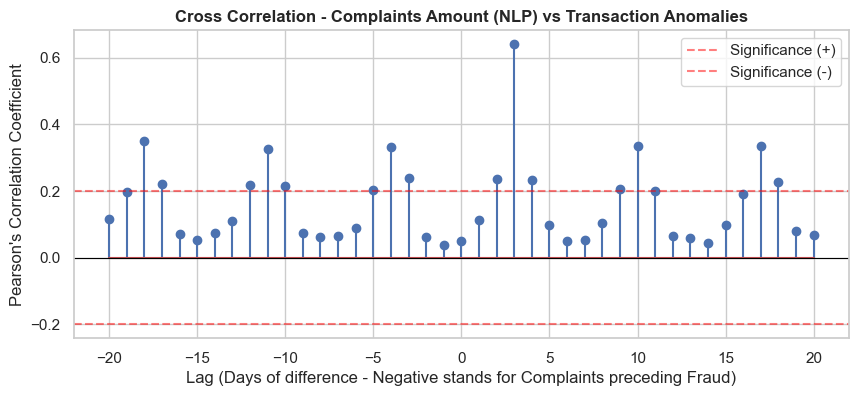

Max correlation of 0.641 in 3 day lag


In [6]:
# Cross Correlation Function
def plot_cross_correlation(x, y, max_lags=20):
    """
    Calculates and plots correlation between time series.
    The negative lag means that X preceds Y
    """
    lags = np.arange(-max_lags, max_lags + 1)
    corrs = [x.corr(y.shift(-lag)) for lag in lags]
    
    plt.figure(figsize=(10, 4))
    plt.stem(lags, corrs)
    plt.axhline(0, color="black", linewidth=0.8)
    plt.axhline(0.2, color="red", linestyle="--", alpha=0.5, label="Significance (+)")
    plt.axhline(-0.2, color="red", linestyle="--", alpha=0.5, label="Significance (-)")
    plt.xlabel("Lag (Days of difference - Negative stands for Complaints preceding Fraud)")
    plt.ylabel("Pearson's Correlation Coefficient")
    plt.title("Cross Correlation - Complaints Amount (NLP) vs Transaction Anomalies", fontweight='bold')
    plt.legend()
    plt.show()

    if len(corrs) > 0:
        max_corr_idx = np.argmax(np.abs(corrs))
        print(f"Max correlation of {corrs[max_corr_idx]:.3f} in {lags[max_corr_idx]} day lag")

# Correlation Analysis
plot_cross_correlation(synthetic_merged["fraud_complaint_volume"], synthetic_merged["autoencoder_anomaly"])

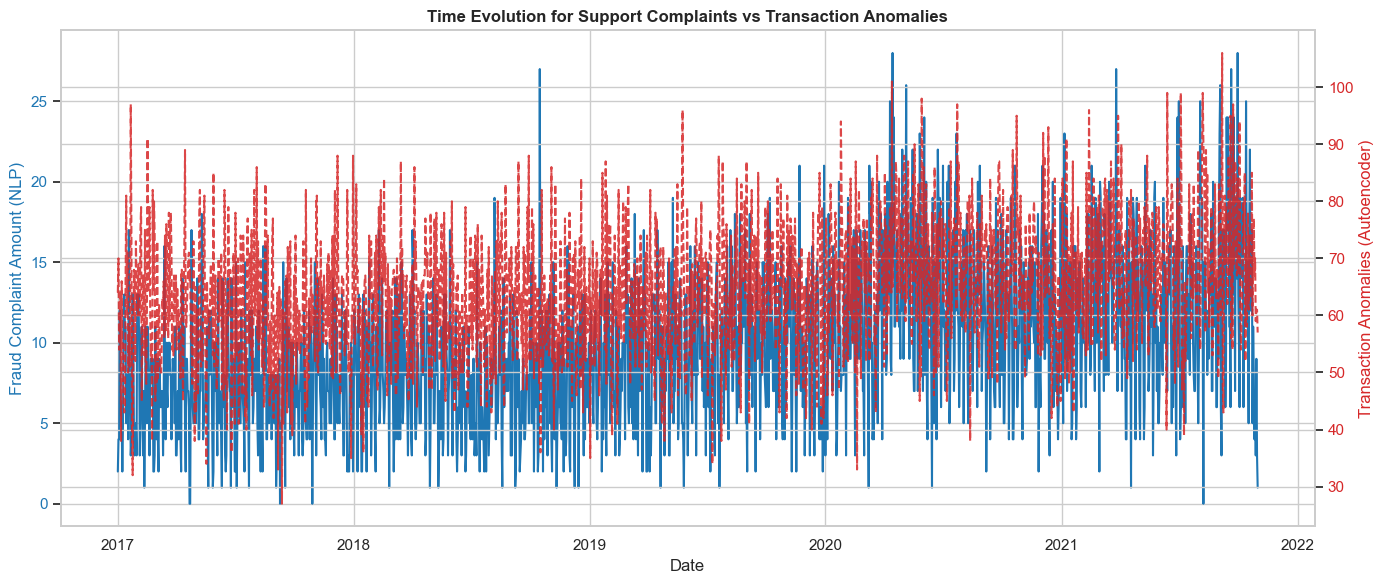

In [7]:
# Double Axis Check
fig, ax1 = plt.subplots(figsize=(14, 6))

color = "tab:blue"
ax1.plot(synthetic_merged.index, synthetic_merged["fraud_complaint_volume"], color=color, label="Customer Complaints")
ax1.set_xlabel("Date")
ax1.set_ylabel("Fraud Complaint Amount (NLP)", color=color)
ax1.tick_params(axis="y", labelcolor=color)

ax2 = ax1.twinx()  
color = "tab:red"
ax2.plot(synthetic_merged.index, synthetic_merged["autoencoder_anomaly"], color=color, linestyle="--", label="Detected Anomalies", alpha=0.85)
ax2.set_ylabel("Transaction Anomalies (Autoencoder)", color=color)
ax2.tick_params(axis="y", labelcolor=color)

plt.title("Time Evolution for Support Complaints vs Transaction Anomalies", fontweight='bold')
fig.tight_layout()
plt.show()